Dataset link = https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset

All code done in Kaggle

working link = https://www.kaggle.com/code/ankitkumar036/planet-disease-prediction/edit

In [2]:
import random
random.seed(0)

import numpy as np
np.random.seed(0)

import tensorflow as tf
tf.random.set_seed(0)

In [34]:
import os
import json
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import models, layers
from tensorflow.keras.utils import plot_model

In [9]:
print(os.listdir("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset"))

print(len(os.listdir("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/segmented")))
print(os.listdir('/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/segmented')[:5])

print(len(os.listdir("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/grayscale")))
print(os.listdir("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/grayscale")[:5])

print(len(os.listdir("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color")))
print(os.listdir("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color")[:5])


['segmented', 'grayscale', 'plantvillage dataset', 'color']
38
['Tomato___Late_blight', 'Tomato___healthy', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Soybean___healthy']
38
['Tomato___Late_blight', 'Tomato___healthy', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Soybean___healthy']
38
['Tomato___Late_blight', 'Tomato___healthy', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Soybean___healthy']


## Number of classes = 38

In [12]:
print(len(os.listdir("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color/Blueberry___healthy")))
print(os.listdir("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color/Blueberry___healthy")[:5])

1502
['c055b51f-83a9-452c-87d9-25e4e3dcf9ef___RS_HL 2513.JPG', 'cbc58efe-eeae-431c-a96c-53c3f9247e89___RS_HL 5069.JPG', '55241e8b-6927-40a9-9d8d-31107ebe1ed6___RS_HL 5508.JPG', 'ba2e2df9-df6b-4abf-ba13-1261464c74d4___RS_HL 2442.JPG', '7b58eff0-e306-4b3f-9cf4-c32780f879e1___RS_HL 5196.JPG']


## Data Preprocessing

In [13]:
# Dataset path
base_dir = "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color"

(256, 256, 3)


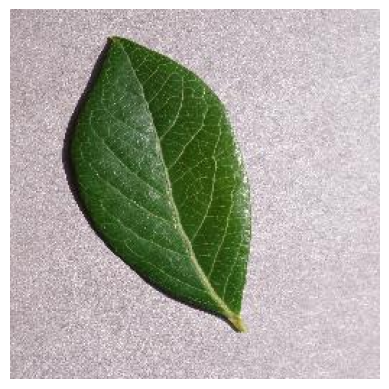

In [14]:
image_path = "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color/Blueberry___healthy/c055b51f-83a9-452c-87d9-25e4e3dcf9ef___RS_HL 2513.JPG"

#Read the image
img = mpimg.imread(image_path)

print(img.shape)
plt.imshow(img)
plt.axis("off")
plt.show()

In [15]:
## Image Parameter

img_size = 224
batch_size = 32

In [16]:
# Image Data Generators

data_gen = ImageDataGenerator(
    rescale = 1./255.,
    validation_split = 0.2
)

In [17]:
## Train generator
train_generator = data_gen.flow_from_directory(
    base_dir,
    target_size = (img_size, img_size),
    batch_size = batch_size,
    subset = "training",
    class_mode = "categorical"
)

Found 43456 images belonging to 38 classes.


In [18]:
## Validation generator
validation_generator = data_gen.flow_from_directory(
    base_dir,
    target_size = (img_size, img_size),
    batch_size = batch_size,
    subset = "validation",
    class_mode = "categorical"
)

Found 10849 images belonging to 38 classes.


## Convolutional Neural Network

In [20]:
## Model Defination
model = models.Sequential()

model.add(layers.Conv2D(32, (3,3), activation = 'relu', input_shape = (img_size, img_size, 3)))
model.add(layers.MaxPooling2D(2,2))

model.add(layers.Conv2D(64, (3,3), activation='relu'))
model.add(layers.MaxPooling2D(2,2))

model.add(layers.Flatten())

model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dense(train_generator.num_classes, activation = 'softmax'))

## compile the model

model.compile(optimizer = 'adam', loss = 'categorical_crossentropy', metrics=['accuracy'])

In [21]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │    47,776,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,805,158 (182.36 MB)

 Trainable params: 47,805,158 (182.36 MB)

 Non-trainable params: 0 (0.00 B)

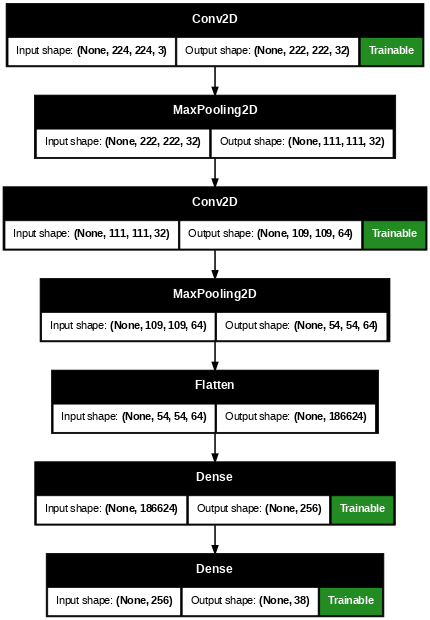

In [23]:
plot_model(
    model,
    to_file = 'plant_disease_parameter.png',
    show_shapes = True,
    show_dtype = False,
    dpi = 55,
    show_trainable = True
)

## Model Training

In [25]:
history = model.fit(
    train_generator,
    steps_per_epoch = train_generator.samples // batch_size,
    epochs = 5,
    validation_data = validation_generator,
    validation_steps = validation_generator.samples // batch_size
)

Epoch 1/5


2026-07-19 02:23:11.530349: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-19 02:23:11.678809: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


   1/1358 ━━━━━━━━━━━━━━━━━━━━ 2:46:08 7s/step - accuracy: 0.0000e+00 - loss: 3.6486

I0000 00:00:1784427794.526282    2119 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1358/1358 ━━━━━━━━━━━━━━━━━━━━ 368s 266ms/step - accuracy: 0.7403 - loss: 0.9314 - val_accuracy: 0.8619 - val_loss: 0.4308
Epoch 2/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 110s 81ms/step - accuracy: 0.9220 - loss: 0.2441 - val_accuracy: 0.8478 - val_loss: 0.5211
Epoch 3/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 113s 83ms/step - accuracy: 0.9613 - loss: 0.1175 - val_accuracy: 0.8687 - val_loss: 0.4923
Epoch 4/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 123s 90ms/step - accuracy: 0.9756 - loss: 0.0757 - val_accuracy: 0.8536 - val_loss: 0.6441
Epoch 5/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 123s 90ms/step - accuracy: 0.9809 - loss: 0.0595 - val_accuracy: 0.8768 - val_loss: 0.6337


## Model Evaluation

In [28]:
## Model Evaluation
print("Evaluating model...")
val_loss, val_accuracy = model.evaluate(validation_generator, steps = validation_generator.samples // batch_size)
print(f"Vallidation accuracy: {val_accuracy * 100:.2f}%")

Evaluating model...
339/339 ━━━━━━━━━━━━━━━━━━━━ 23s 68ms/step - accuracy: 0.8768 - loss: 0.6337
Vallidation accuracy: 87.68%


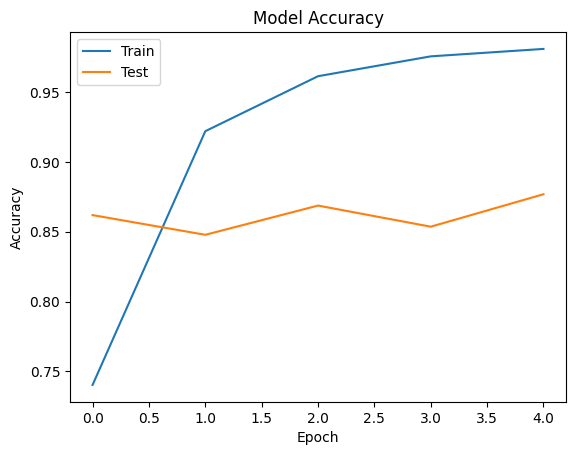

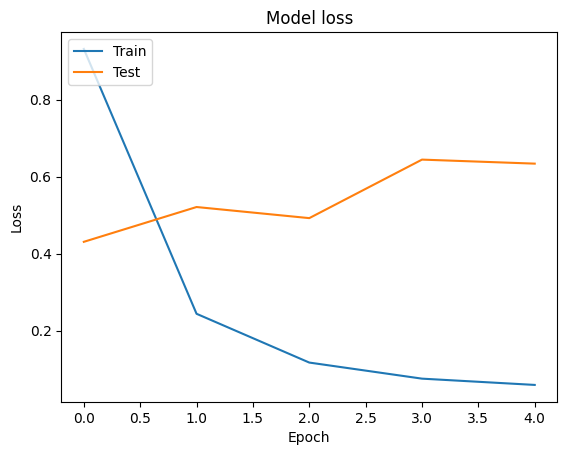

In [29]:
## Plot training & validation accuracy values

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

## Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

## Building Predictive System

In [30]:
## Functio to load and process the image

def load_and_preprocess_image(image_path, target_size=(224, 224)):
    #load the image
    img = Image.open(image_path)
    img = img.resize(target_size)
    img_array = np.array(img)
    # Add Batch Dimension
    img_array = np.expand_dims(img_array, axis=0)
    # scale the image value
    img_array = img_array.astype('float') / 255.
    return img_array

## function to predict the class

def predict_image_class(model, image_path, class_indices):
    preprocessed_img = load_and_preprocess_image(image_path)
    predictions = model.predict(preprocessed_img)
    predicted_class_index = np.argmax(predictions, axis=1)[0]
    predicted_class_name = class_indices[predicted_class_index]
    return predicted_class_name

In [31]:
## create mapping from class indices to class names

class_indices = {v: k for k, v in train_generator.class_indices.items()}

In [32]:
class_indices

{0: 'Apple___Apple_scab',
 1: 'Apple___Black_rot',
 2: 'Apple___Cedar_apple_rust',
 3: 'Apple___healthy',
 4: 'Blueberry___healthy',
 5: 'Cherry_(including_sour)___Powdery_mildew',
 6: 'Cherry_(including_sour)___healthy',
 7: 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 8: 'Corn_(maize)___Common_rust_',
 9: 'Corn_(maize)___Northern_Leaf_Blight',
 10: 'Corn_(maize)___healthy',
 11: 'Grape___Black_rot',
 12: 'Grape___Esca_(Black_Measles)',
 13: 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 14: 'Grape___healthy',
 15: 'Orange___Haunglongbing_(Citrus_greening)',
 16: 'Peach___Bacterial_spot',
 17: 'Peach___healthy',
 18: 'Pepper,_bell___Bacterial_spot',
 19: 'Pepper,_bell___healthy',
 20: 'Potato___Early_blight',
 21: 'Potato___Late_blight',
 22: 'Potato___healthy',
 23: 'Raspberry___healthy',
 24: 'Soybean___healthy',
 25: 'Squash___Powdery_mildew',
 26: 'Strawberry___Leaf_scorch',
 27: 'Strawberry___healthy',
 28: 'Tomato___Bacterial_spot',
 29: 'Tomato___Early_blight',
 30: '

In [36]:
## saving the class names as json files
json.dump(class_indices, open('class_indices.json', 'w'))

## save the model

In [37]:
model.save("plant_disease_prediction_model.h5")